In [2]:
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV

In [4]:
!pip install pyarrow



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 10.9 MB/s  0:00:03 eta 0:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [6]:
pip install -U pyarrow


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install --upgrade pip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 14.0 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.0.1
    Uninstalling pip-26.0.1:
      Successfully uninstalled pip-26.0.1
Note: you may need to restart the kernel to use updated packages.


In [10]:
import os
os.chdir('/Users/azharbolatbek/Desktop')
print(os.getcwd())

/Users/azharbolatbek/Desktop


In [13]:
print(os.listdir('.'))


['Flask', 'Visual Studio Code.app', 'P03_test.pq', 'NFACTORIAL DATA', 'vid2026', 'AZHAR BOLATBEK-cv..pdf', '.DS_Store', 'YONSEI', '04.提携管理寮寮則（トラスティ東村山のみ）20240401（多言語版）.pdf', '.localized', 'Neural Networks ', '~$midterm econometrics.xlsx', 'Jeju horizontal ', 'PythonNew', '~$ Template.docx', 'P03_SCORING.ipynb', 'Kyoto summer 2023', '~$EconometricsPS7.xlsx', 'Adobe Photoshop 2025', '~$mmary Financial acc 1.docx', 'urban_data', 'Statistics book.pdf', 'P03_train.pq', 'all docs', '~$- Azhar.docx', 'Python_1', 'Untitled design.jpg.JPG']


**Кредитный скоринг** является важной банковской задачей. 

Стандартный подход заключается в построении классических моделей машинного обучения, таких как логистическая регрессия и градиентный бустинг на табличных данных, в том числе с использованием *агрегирования* из некоторых последовательных данных, таких как истории транзакций клиентов. 


### Описание полей:
- id - identifier of the application
- <span style = 'color : red'> **flag** </span> - target (целевая переменная)
- pre_since_opened - days from credit opening date to data collection date
- pre_since_confirmed - days from credit information confirmation date till data collection date
- pre_pterm - planned number of days from credit opening date to closing date
- pre_fterm - actual number of days from credit opening date to closing date
- pre_till_pclose - planned number of days from data collection date until loan closing date
- pre_till_fclose - actual number of days from data collection date until loan closing date
- pre_loans_credit_limit - credit limit
- pre_loans_next_pay_summ - amount of the next loan payment
- pre_loans_outstanding - outstanding loan amount
- pre_loans_total_overdue - current overdue amount
- pre_loans_max_overdue_sum - maximum overdue amount
- pre_loans_credit_cost_rate - total cost of credit
- pre_loans5 - number of delinquencies of up to 5 days
- pre_loans530 - number of delinquencies from 5 to 30 days
- pre_loans3060 - number of delinquencies from 30 to 60 days
- pre_loans6090 - number of delinquencies from 60 to 90 days
- pre_loans90 - number of delinquencies of more than 90 days
- is_zero_loans_5 - flag: no delinquencies of up to 5 days
- is_zero_loans_530 - flag: no delinquencies of 5 to 30 days
- is_zero_loans_3060 - flag: no delinquencies of 30 to 60 days
- is_zero_loans_6090 - flag: no delinquencies of 60 to 90 days
- is_zero_loans90 - flag: no delinquencies of more than 90 days
- pre_util - ratio of outstanding loan amount to credit limit
- pre_over2limit - ratio of currently overdue debt to credit limit
- pre_maxover2limit - ratio of maximum overdue debt to credit limit
- is_zero_util - flag: ratio of outstanding loan amount to credit limit equals 0
- is_zero_over2limit - flag: ratio of current overdue debt to credit limit equals 0
- is_zero_maxover2limit - flag: ratio of maximum overdue debt to credit limit equals 0
- **<span style = 'color : blue'> enc_paym_{0…n} </span>** - monthly payment statuses of the last n months
- enc_loans_account_holder_type - type of relation to the loan
- enc_loans_credit_status - credit status
- enc_loans_account_cur - currency of the loan
- enc_loans_credit_type - credit type
- pclose_flag - flag: planned number of days from opening date to closing date of the loan
- fclose_flag - flag: actual number of days from credit opening date to closing date undefined

In [90]:
df_train['pre_since_opened'].corr(df_train['pre_since_confirmed'])

np.float64(-0.0023145686365102095)

In [91]:
df_train.head()

,id,flag,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,41794,0,3,9,16,9,15,14,16,3,...,3,3,3,4,1,3,4,1,0,0
1,160704,0,9,6,0,1,0,4,1,3,...,3,3,3,4,1,2,3,1,0,0
2,41771,0,12,16,14,8,10,11,10,2,...,3,3,3,4,1,2,3,1,0,1
3,160727,0,7,9,17,16,14,8,14,3,...,3,3,3,4,1,2,4,1,0,0
4,160729,0,9,9,4,8,1,11,10,3,...,3,3,3,4,1,2,3,1,1,1


In [99]:
df_train["pre_since_confirmed"].value_counts()

pre_since_confirmed
9     68760
6     23001
10    17589
16    14700
2     14667
0     11014
5      5835
1      4724
13     3998
3      2858
17     2173
12     1520
11     1286
8      1187
14      916
4       428
7       342
15        2
Name: count, dtype: int64

# Open files

In [6]:
df_train = pd.read_parquet('./parquets/P03_train.pq')
df_test = pd.read_parquet('./parquets/P03_test.pq')

FileNotFoundError: [Errno 2] No such file or directory: './parquets/P03_train.pq'

In [14]:
import os
print("Current dir:", os.getcwd())
print("Contents:", os.listdir('.'))

Current dir: /Users/azharbolatbek/Desktop
Contents: ['Flask', 'Visual Studio Code.app', 'P03_test.pq', 'NFACTORIAL DATA', 'vid2026', 'AZHAR BOLATBEK-cv..pdf', '.DS_Store', 'YONSEI', '04.提携管理寮寮則（トラスティ東村山のみ）20240401（多言語版）.pdf', '.localized', 'Neural Networks ', '~$midterm econometrics.xlsx', 'Jeju horizontal ', 'PythonNew', '~$ Template.docx', 'P03_SCORING.ipynb', 'Kyoto summer 2023', '~$EconometricsPS7.xlsx', 'Adobe Photoshop 2025', '~$mmary Financial acc 1.docx', 'urban_data', 'Statistics book.pdf', 'P03_train.pq', 'all docs', '~$- Azhar.docx', 'Python_1', 'Untitled design.jpg.JPG']


In [2]:
import os
os.chdir(os.path.expanduser('~/Desktop'))

import pandas as pd
df_train = pd.read_parquet('P03_train.pq')
df_test = pd.read_parquet('P03_test.pq')

In [8]:
df_train.head()

,id,flag,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,41794,0,3,9,16,9,15,14,16,3,...,3,3,3,4,1,3,4,1,0,0
1,160704,0,9,6,0,1,0,4,1,3,...,3,3,3,4,1,2,3,1,0,0
2,41771,0,12,16,14,8,10,11,10,2,...,3,3,3,4,1,2,3,1,0,1
3,160727,0,7,9,17,16,14,8,14,3,...,3,3,3,4,1,2,4,1,0,0
4,160729,0,9,9,4,8,1,11,10,3,...,3,3,3,4,1,2,3,1,1,1


In [17]:
df_train.shape

(175000, 61)

In [18]:
df_test.shape

(75000, 60)

In [19]:
set(df_train.columns) == set(df_test.columns)


False

In [20]:
list(df_train.columns) == list(df_test.columns)


False

In [ ]:
in_train_not_test = set(df_train.columns) - set(df_test.columns)
in_test_not_train = set(df_test.columns) - set(df_train.columns)

print("In train but not test:", in_train_not_test)
print("In test but not train:", in_test_not_train)
#set() is just empty set. 

In train but not test: {'flag'}
In test but not train: set()


In [23]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 175000 entries, 0 to 174999
Data columns (total 61 columns):
 #   Column                         Non-Null Count   Dtype
---  ------                         --------------   -----
 0   id                             175000 non-null  int64
 1   flag                           175000 non-null  int64
 2   pre_since_opened               175000 non-null  int64
 3   pre_since_confirmed            175000 non-null  int64
 4   pre_pterm                      175000 non-null  int64
 5   pre_fterm                      175000 non-null  int64
 6   pre_till_pclose                175000 non-null  int64
 7   pre_till_fclose                175000 non-null  int64
 8   pre_loans_credit_limit         175000 non-null  int64
 9   pre_loans_next_pay_summ        175000 non-null  int64
 10  pre_loans_outstanding          175000 non-null  int64
 11  pre_loans_total_overdue        175000 non-null  int64
 12  pre_loans_max_overdue_sum      175000 non-null  int64
 13  pre_loans_

In [43]:
(df_train.isnull().sum() > 0).sum()


np.int64(0)

In [29]:
print(df_train.select_dtypes(include='object').dtypes)


Series([], dtype: object)


In [30]:
non_numeric_cols = df_train.select_dtypes(exclude=['int64', 'float64']).columns.tolist()
print(non_numeric_cols)

[]


In [ ]:
df_train.corr()

,id,flag,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
id,1.000000,0.002102,0.020936,0.010621,-0.022938,0.002555,-0.026467,0.011450,-0.002617,0.007051,...,0.012063,0.011600,0.011560,-0.003190,0.003218,-0.021205,-0.022709,0.000737,0.037522,0.036921
flag,0.002102,1.000000,0.029626,0.008440,-0.011297,0.000339,-0.007038,-0.006622,0.013717,-0.001521,...,0.022628,0.022405,0.021384,0.013934,-0.010738,0.001418,0.034343,-0.001310,0.011327,0.004883
pre_since_opened,0.020936,0.029626,1.000000,-0.002315,-0.057657,0.005051,0.014638,-0.008549,0.000855,0.030396,...,0.091865,0.084003,0.071315,0.040486,-0.013674,-0.186706,0.020602,0.001233,0.066586,0.099857
pre_since_confirmed,0.010621,0.008440,-0.002315,1.000000,-0.034336,0.025756,0.004854,-0.089571,0.002175,0.004354,...,-0.024163,-0.023580,-0.023594,-0.003368,-0.012370,-0.006848,0.029785,0.002971,0.050797,-0.038394
pre_pterm,-0.022938,-0.011297,-0.057657,-0.034336,1.000000,-0.002851,0.345057,-0.072617,-0.006491,0.003187,...,0.097252,0.098604,0.100807,0.027947,-0.051734,0.062044,0.060892,0.001660,-0.449935,-0.199494
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
enc_loans_credit_status,-0.021205,0.001418,-0.186706,-0.006848,0.062044,-0.089588,0.052557,-0.123936,0.014907,-0.080738,...,-0.044224,-0.044445,-0.043969,-0.033544,-0.055724,1.000000,0.070468,0.023987,-0.156215,-0.408616
enc_loans_credit_type,-0.022709,0.034343,0.020602,0.029785,0.060892,0.119639,0.172599,-0.034105,0.081180,-0.032835,...,0.076096,0.075218,0.074331,0.094137,-0.314365,0.070468,1.000000,-0.016126,-0.090070,-0.245440
enc_loans_account_cur,0.000737,-0.001310,0.001233,0.002971,0.001660,-0.001319,0.004069,-0.009422,-0.002784,-0.002659,...,0.001159,0.000070,-0.000818,-0.014400,0.007714,0.023987,-0.016126,1.000000,-0.007260,-0.010553
pclose_flag,0.037522,0.011327,0.066586,0.050797,-0.449935,-0.066448,-0.649915,0.271993,0.053792,-0.004037,...,-0.046042,-0.047709,-0.052040,0.105459,0.020028,-0.156215,-0.090070,-0.007260,1.000000,0.554479


In [37]:
df_train["flag"].value_counts()

flag
0    169574
1      5426
Name: count, dtype: int64

In [89]:
df_train['flag'].value_counts(normalize=True)


flag
0    0.968994
1    0.031006
Name: proportion, dtype: float64

In [27]:
len(df_train)

175000

In [38]:
import matplotlib.pyplot as plt

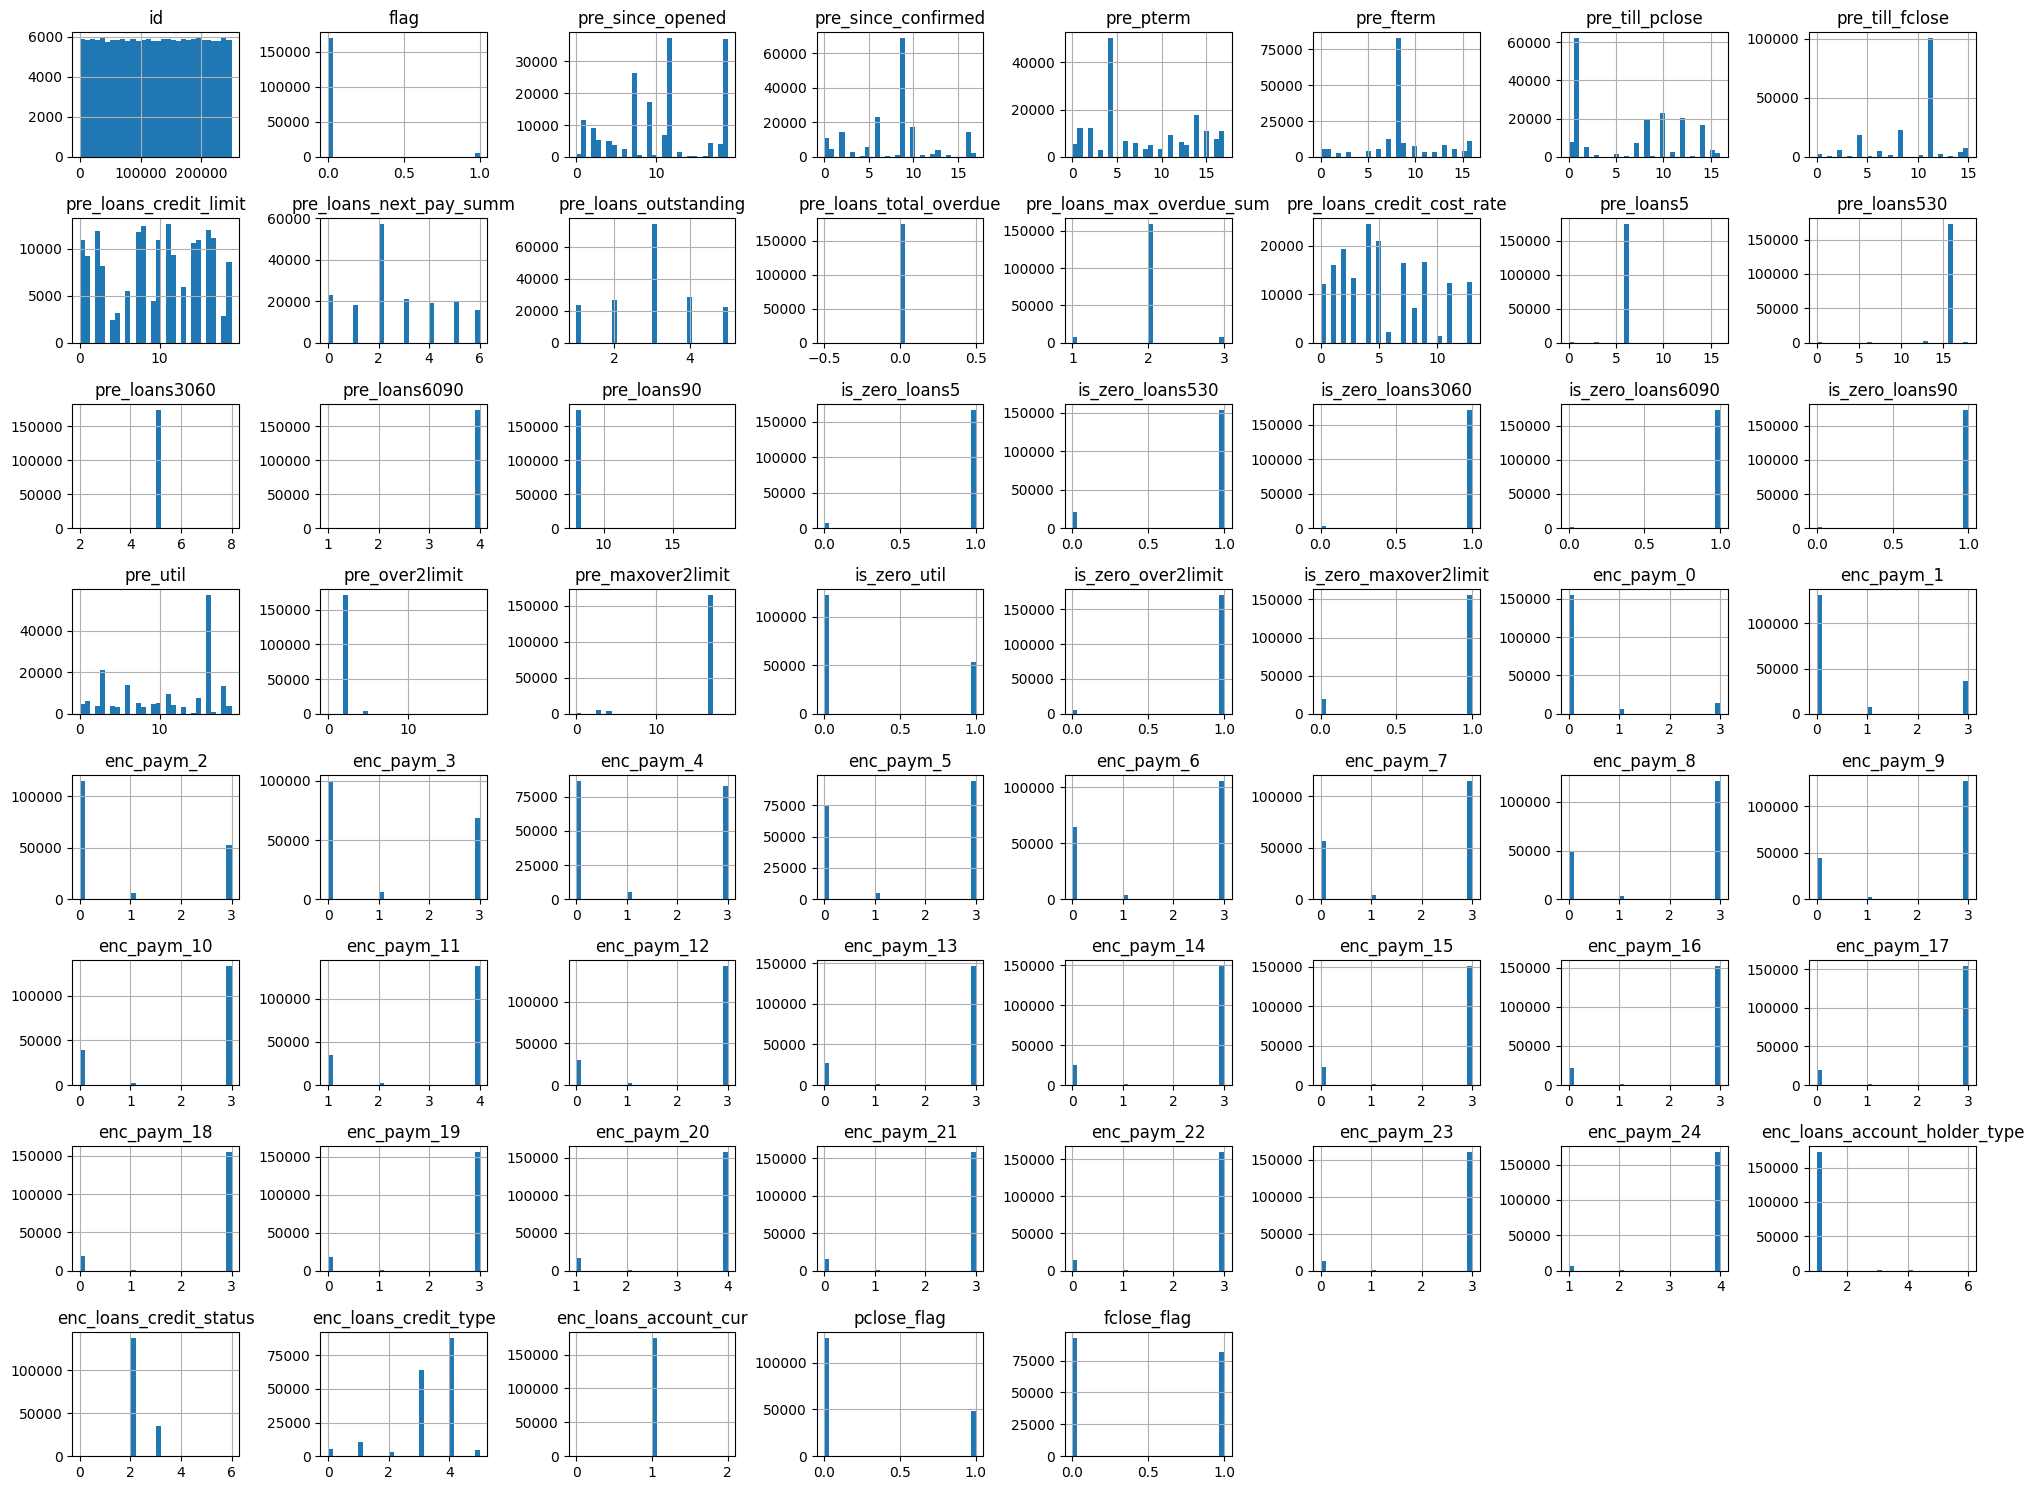

In [39]:
df_train.hist(figsize=(20, 15), bins=30)
plt.tight_layout()
plt.show()

In [42]:
df_train["pre_loans_total_overdue"].value_counts()

pre_loans_total_overdue
0    175000
Name: count, dtype: int64

In [47]:
df_train.columns

Index(['id', 'flag', 'pre_since_opened', 'pre_since_confirmed', 'pre_pterm',
       'pre_fterm', 'pre_till_pclose', 'pre_till_fclose',
       'pre_loans_credit_limit', 'pre_loans_next_pay_summ',
       'pre_loans_outstanding', 'pre_loans_total_overdue',
       'pre_loans_max_overdue_sum', 'pre_loans_credit_cost_rate', 'pre_loans5',
       'pre_loans530', 'pre_loans3060', 'pre_loans6090', 'pre_loans90',
       'is_zero_loans5', 'is_zero_loans530', 'is_zero_loans3060',
       'is_zero_loans6090', 'is_zero_loans90', 'pre_util', 'pre_over2limit',
       'pre_maxover2limit', 'is_zero_util', 'is_zero_over2limit',
       'is_zero_maxover2limit', 'enc_paym_0', 'enc_paym_1', 'enc_paym_2',
       'enc_paym_3', 'enc_paym_4', 'enc_paym_5', 'enc_paym_6', 'enc_paym_7',
       'enc_paym_8', 'enc_paym_9', 'enc_paym_10', 'enc_paym_11', 'enc_paym_12',
       'enc_paym_13', 'enc_paym_14', 'enc_paym_15', 'enc_paym_16',
       'enc_paym_17', 'enc_paym_18', 'enc_paym_19', 'enc_paym_20',
       'enc_paym_21'

In [48]:
df_train.corr(numeric_only=True)['flag'].drop(['flag', 'id']).sort_values(ascending=False)

enc_paym_1                       0.058240
enc_paym_2                       0.057118
enc_paym_3                       0.054696
enc_paym_4                       0.051555
enc_paym_5                       0.047368
enc_paym_6                       0.045844
enc_paym_7                       0.042857
enc_paym_8                       0.040645
enc_paym_9                       0.037363
enc_paym_0                       0.036926
enc_paym_10                      0.035237
enc_paym_11                      0.034524
enc_loans_credit_type            0.034343
enc_paym_12                      0.033341
enc_paym_13                      0.032532
enc_paym_14                      0.031285
enc_paym_15                      0.030394
pre_since_opened                 0.029626
enc_paym_16                      0.028633
enc_paym_17                      0.026621
enc_paym_18                      0.026021
enc_paym_19                      0.025350
enc_paym_20                      0.023964
enc_paym_21                      0

In [46]:
df_train["pre_loans90"].corr(df_train["flag"])

np.float64(0.0022195134484952763)

In [45]:
df_test["pre_loans_total_overdue"].value_counts()

pre_loans_total_overdue
0    75000
Name: count, dtype: int64

In [40]:
df_train["pre_loans_max_overdue_sum"].value_counts()

pre_loans_max_overdue_sum
2    159412
3      7991
1      7597
Name: count, dtype: int64

In [39]:
df_train["is_zero_loans90"].value_counts(normalize=True)

is_zero_loans90
1    0.992697
0    0.007303
Name: proportion, dtype: float64

<Axes: xlabel='flag', ylabel='is_zero_loans90'>

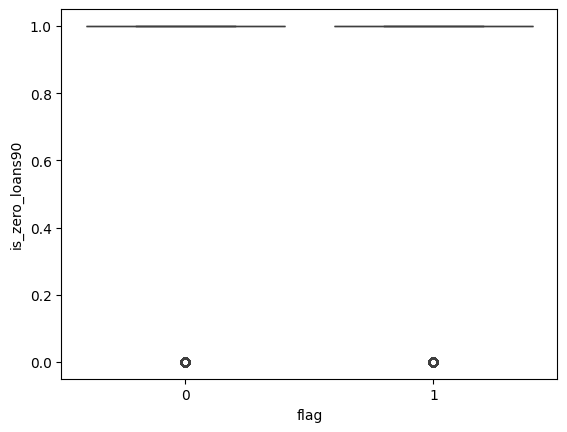

In [37]:
import seaborn as sns
sns.boxplot(x='flag', y='is_zero_loans90', data=df_train)


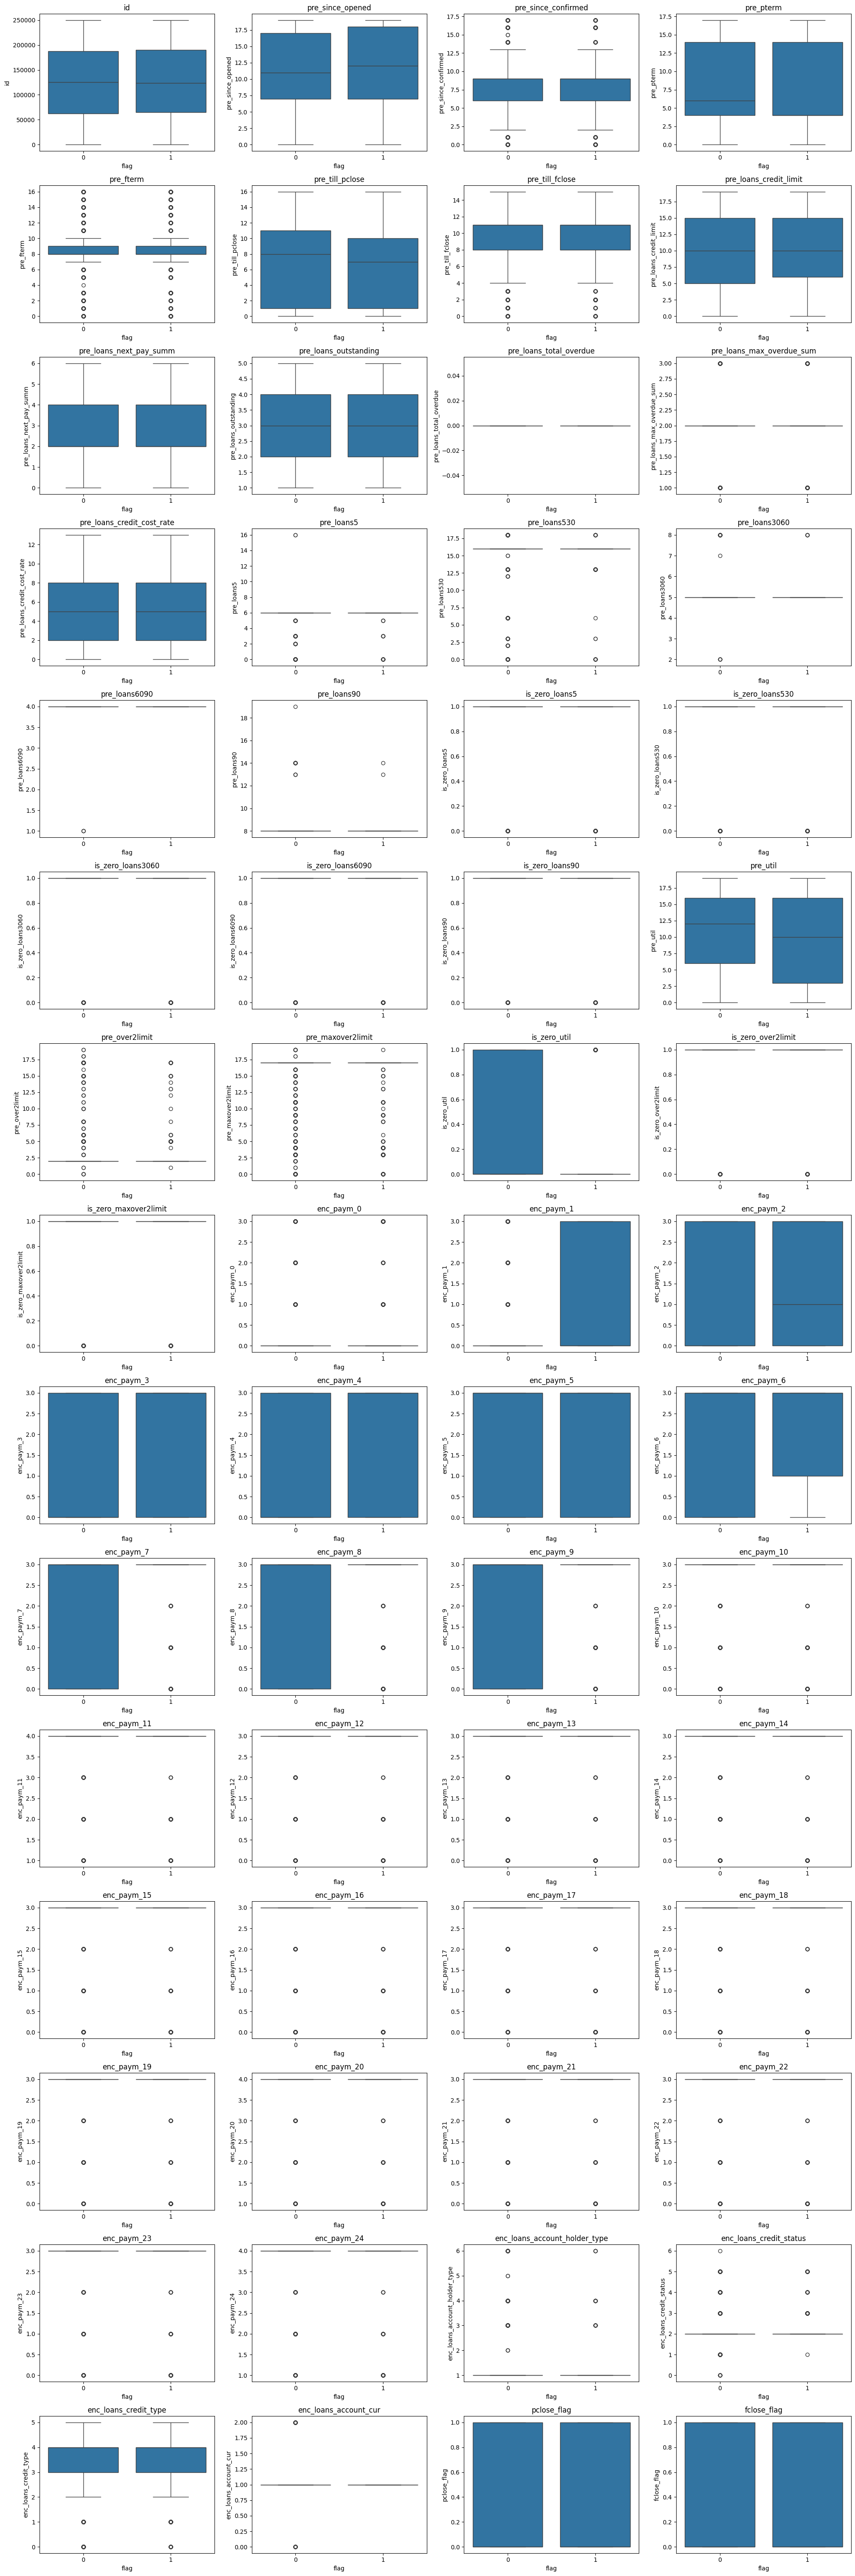

In [41]:

import seaborn as sns

numeric_cols = [c for c in df_train.select_dtypes(include='number').columns if c != 'flag']

n_cols = 4
n_rows = -(-len(numeric_cols) // n_cols)  # ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(x='flag', y=col, data=df_train, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

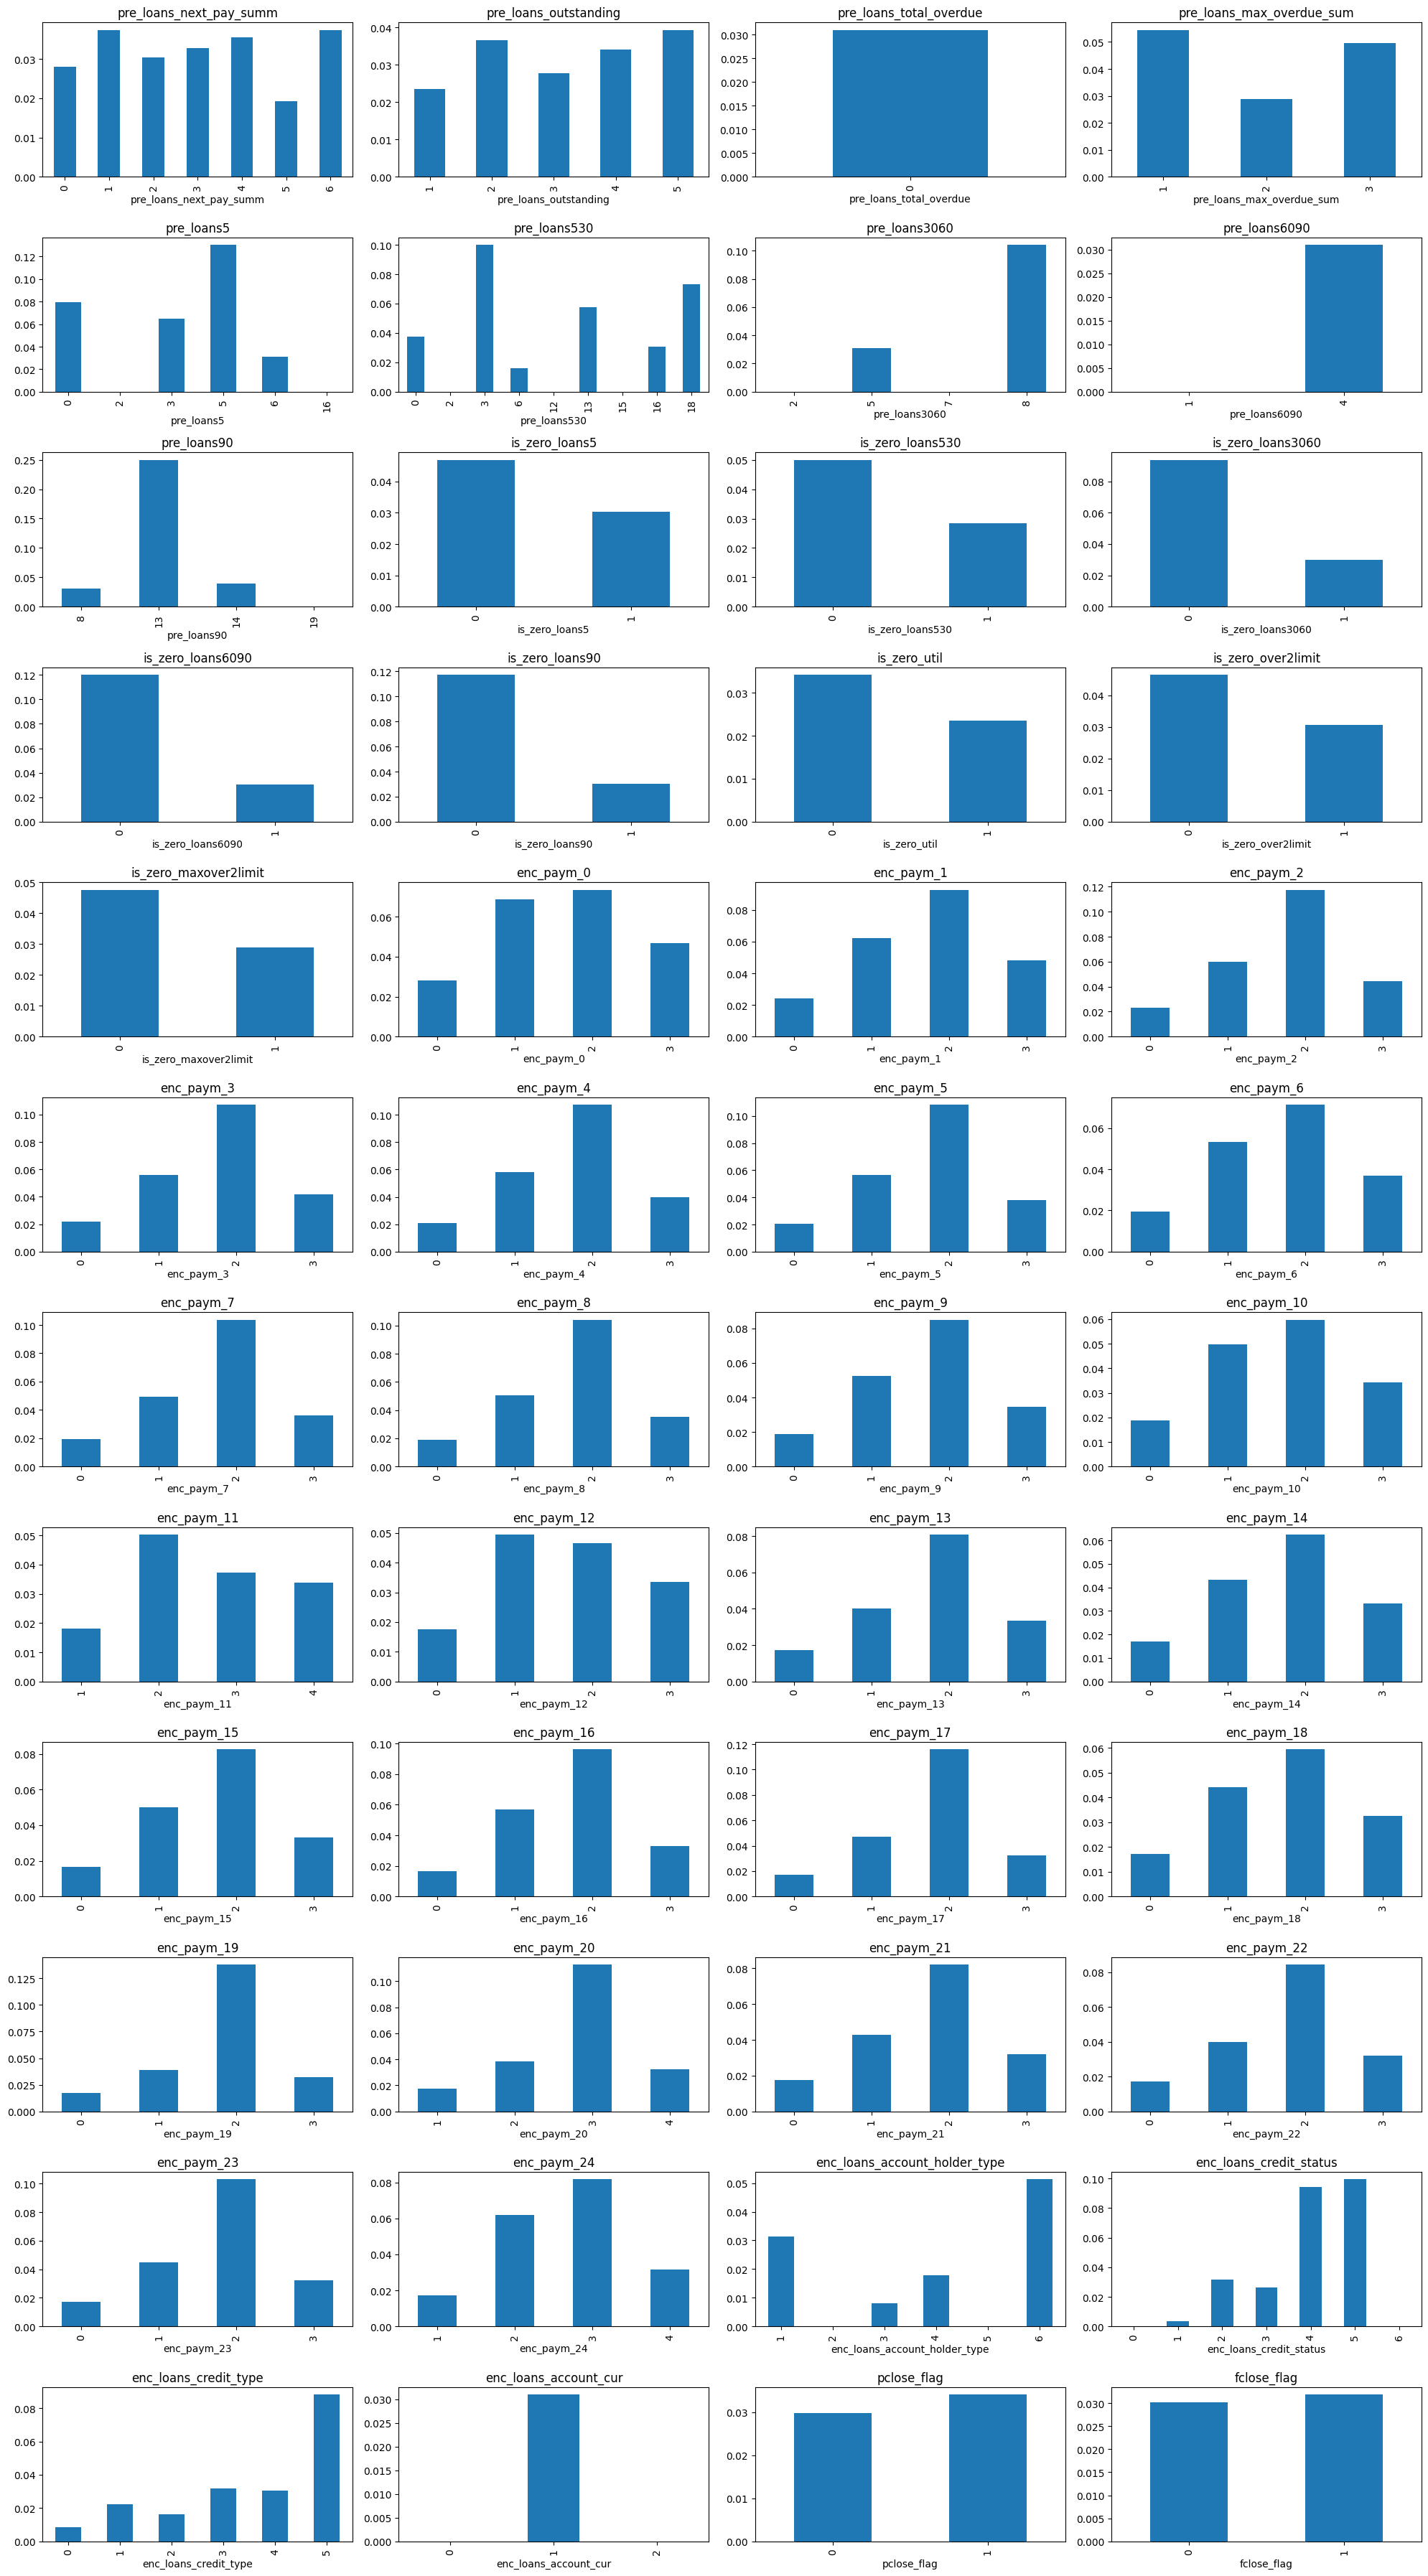

In [48]:


discrete_cols = [c for c in df_train.columns if df_train[c].nunique() <= 10 and c != 'flag']

n_cols = 4
n_rows = -(-len(discrete_cols) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows*3))
axes = axes.flatten()

for i, col in enumerate(discrete_cols):
    df_train.groupby(col)['flag'].mean().plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [3]:
df_train["enc_loans_account_cur"].value_counts()

enc_loans_account_cur
1    174862
2        87
0        51
Name: count, dtype: int64

In [9]:
cols_with_one_value = [col for col in df_train.columns if df_train[col].nunique() == 1]
print(cols_with_one_value)

['pre_loans_total_overdue']


In [8]:
df_train["enc_loans_account_cur"].corr(df_train["flag"])

np.float64(-0.0013104361014501015)

In [4]:
df_test["enc_loans_account_cur"].value_counts()

enc_loans_account_cur
1    74938
2       33
0       29
Name: count, dtype: int64

In [5]:
df_train["pre_loans6090"].value_counts()

pre_loans6090
4    174997
1         3
Name: count, dtype: int64

In [7]:
df_train["pre_loans6090"].corr(df_train["flag"])

np.float64(0.0007406373132024955)

In [6]:
df_test["pre_loans6090"].value_counts()

pre_loans6090
4    74999
1        1
Name: count, dtype: int64

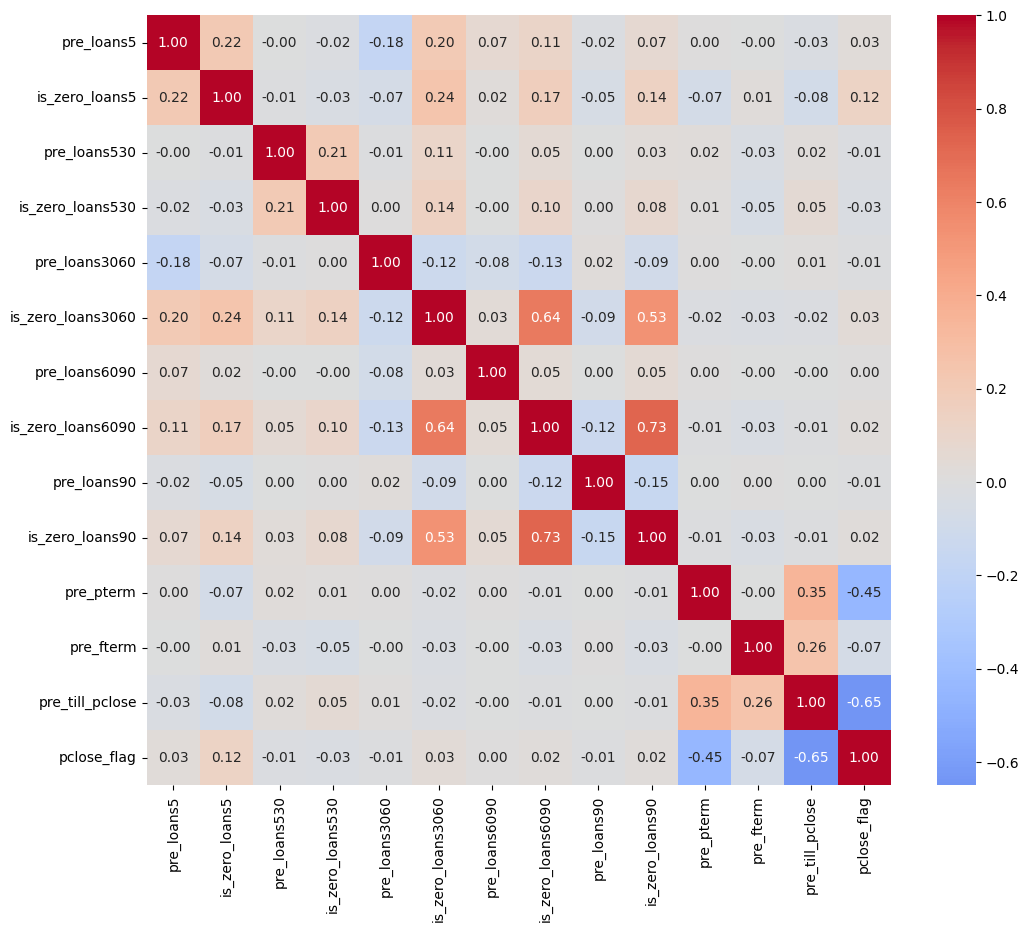

In [47]:
suspect_cols = ['pre_loans5','is_zero_loans5','pre_loans530','is_zero_loans530',
                'pre_loans3060','is_zero_loans3060','pre_loans6090','is_zero_loans6090',
                'pre_loans90','is_zero_loans90',
                'pre_pterm','pre_fterm','pre_till_pclose','pclose_flag']

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12,10))
sns.heatmap(df_train[suspect_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

In [45]:
[c for c in df_train.columns if 'zero' in c.lower()]

['is_zero_loans5',
 'is_zero_loans530',
 'is_zero_loans3060',
 'is_zero_loans6090',
 'is_zero_loans90',
 'is_zero_util',
 'is_zero_over2limit',
 'is_zero_maxover2limit']

In [46]:
[c for c in df_train.columns if 'loans' in c.lower() or 'pterm' in c.lower() or 'fterm' in c.lower() or 'pclose' in c.lower()]

['pre_pterm',
 'pre_fterm',
 'pre_till_pclose',
 'pre_loans_credit_limit',
 'pre_loans_next_pay_summ',
 'pre_loans_outstanding',
 'pre_loans_total_overdue',
 'pre_loans_max_overdue_sum',
 'pre_loans_credit_cost_rate',
 'pre_loans5',
 'pre_loans530',
 'pre_loans3060',
 'pre_loans6090',
 'pre_loans90',
 'is_zero_loans5',
 'is_zero_loans530',
 'is_zero_loans3060',
 'is_zero_loans6090',
 'is_zero_loans90',
 'enc_loans_account_holder_type',
 'enc_loans_credit_status',
 'enc_loans_credit_type',
 'enc_loans_account_cur',
 'pclose_flag']

In [9]:
target = "flag"
X = df_train.drop(columns=[target])
y = df_train[target]


print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (175000, 60)
y shape: (175000,)


In [10]:
X.drop(columns="id", inplace=True)

In [34]:
X

,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,pre_loans_outstanding,pre_loans_total_overdue,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,3,9,16,9,15,14,16,3,3,0,...,3,3,3,4,1,3,4,1,0,0
1,9,6,0,1,0,4,1,3,4,0,...,3,3,3,4,1,2,3,1,0,0
2,12,16,14,8,10,11,10,2,3,0,...,3,3,3,4,1,2,3,1,0,1
3,7,9,17,16,14,8,14,3,5,0,...,3,3,3,4,1,2,4,1,0,0
4,9,9,4,8,1,11,10,3,3,0,...,3,3,3,4,1,2,3,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174995,12,6,4,8,7,2,19,2,3,0,...,3,3,3,4,1,3,5,1,0,0
174996,12,5,4,8,7,11,4,2,3,0,...,3,3,3,4,1,2,4,1,0,1
174997,12,9,3,8,1,11,19,2,4,0,...,3,3,3,4,1,2,4,1,0,1
174998,12,9,4,8,1,11,0,5,3,0,...,3,3,3,4,1,2,3,1,1,1


In [11]:
from sklearn.model_selection import train_test_split, GridSearchCV
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report


In [12]:

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (140000, 59)
y_train shape: (140000,)
X_test shape: (35000, 59)
y_test shape: (35000,)


In [13]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote shape:", X_train_smote.shape)
X_train_smote.head()

X_train_smote shape: (271292, 59)


,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,pre_loans_outstanding,pre_loans_total_overdue,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,12,16,4,8,1,11,14,0,5,0,...,3,3,3,4,1,2,3,1,1,1
1,19,9,7,11,1,11,13,1,3,0,...,3,3,3,4,1,2,4,1,0,0
2,11,16,14,7,14,8,15,0,1,0,...,3,3,3,4,1,2,4,1,0,0
3,12,16,3,8,1,11,5,2,3,0,...,3,3,3,4,1,2,5,1,0,1
4,7,9,2,14,8,8,10,1,2,0,...,3,3,3,4,1,2,4,1,0,0


In [73]:
y_train_smote.value_counts()

flag
0    135646
1    135646
Name: count, dtype: int64

In [60]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

clf = make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=42))

params = {
    "gradientboostingclassifier__n_estimators": range(20, 31, 5),
    "gradientboostingclassifier__max_depth": range(2, 5)
}

model = GridSearchCV(clf, param_grid=params, cv=5, n_jobs=-1, verbose=1)

In [74]:
model.fit(X_train_smote, y_train_smote)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'gradientboostingclassifier__max_depth': range(2, 5), 'gradientboostingclassifier__n_estimators': range(20, 31, 5)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candid

In [75]:
results = pd.DataFrame(model.cv_results_)
results.sort_values("rank_test_score").head(10)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_gradientboostingclassifier__max_depth,param_gradientboostingclassifier__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
8,18.632380,2.268372,0.057173,0.013938,4,30,"{'gradientboostingclassifier__max_depth': 4, '...",0.745038,0.769605,0.770541,0.766468,0.769085,0.764147,0.009650,1
7,21.169479,0.225093,0.088443,0.018954,4,25,"{'gradientboostingclassifier__max_depth': 4, '...",0.735878,0.758307,0.757492,0.759722,0.760035,0.754287,0.009251,2
6,16.943100,0.435702,0.095936,0.013342,4,20,"{'gradientboostingclassifier__max_depth': 4, '...",0.723345,0.744190,0.743466,0.747724,0.746176,0.740980,0.008944,3
5,18.316712,0.241197,0.097528,0.019066,3,30,"{'gradientboostingclassifier__max_depth': 3, '...",0.712877,0.733058,0.734067,0.731671,0.728814,0.728097,0.007813,4
4,15.028609,0.282183,0.094993,0.012942,3,25,"{'gradientboostingclassifier__max_depth': 3, '...",0.708933,0.723530,0.725202,0.724207,0.722898,0.720954,0.006059,5
3,12.400207,0.242795,0.086145,0.013573,3,20,"{'gradientboostingclassifier__max_depth': 3, '...",0.699681,0.711587,0.714033,0.711029,0.711434,0.709553,0.005047,6
2,12.564418,0.132631,0.094476,0.008683,2,30,"{'gradientboostingclassifier__max_depth': 2, '...",0.683868,0.702962,0.699860,0.700007,0.700302,0.697400,0.006860,7
1,10.415615,0.215621,0.107592,0.015382,2,25,"{'gradientboostingclassifier__max_depth': 2, '...",0.681214,0.691351,0.699049,0.694607,0.696413,0.692527,0.006186,8
0,8.556914,0.147265,0.106239,0.010999,2,20,"{'gradientboostingclassifier__max_depth': 2, '...",0.674432,0.685158,0.685834,0.688839,0.688175,0.684488,0.005214,9


In [80]:
model.best_params_

{'gradientboostingclassifier__max_depth': 4,
 'gradientboostingclassifier__n_estimators': 30}

In [77]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, model.predict(X_test)))

y_proba = model.predict_proba(X_test)[:, 1]  # probability of class 1
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

           0       0.98      0.73      0.84     33928
           1       0.05      0.47      0.10      1072

    accuracy                           0.72     35000
   macro avg       0.52      0.60      0.47     35000
weighted avg       0.95      0.72      0.82     35000

ROC-AUC: 0.6587722557558235


In [82]:
from sklearn.metrics import classification_report, roc_auc_score

print("=== Train ===")
print(classification_report(y_train_smote, model.predict(X_train_smote)))
y_proba_train = model.predict_proba(X_train_smote)[:, 1]
print("ROC-AUC (train):", roc_auc_score(y_train_smote, y_proba_train))

print("\n=== Test ===")
print(classification_report(y_test, model.predict(X_test)))
y_proba_test = model.predict_proba(X_test)[:, 1]
print("ROC-AUC (test):", roc_auc_score(y_test, y_proba_test))

=== Train ===
              precision    recall  f1-score   support

           0       0.78      0.73      0.75    135646
           1       0.74      0.79      0.77    135646

    accuracy                           0.76    271292
   macro avg       0.76      0.76      0.76    271292
weighted avg       0.76      0.76      0.76    271292

ROC-AUC (train): 0.8459061193419087

=== Test ===
              precision    recall  f1-score   support

           0       0.98      0.73      0.84     33928
           1       0.05      0.47      0.10      1072

    accuracy                           0.72     35000
   macro avg       0.52      0.60      0.47     35000
weighted avg       0.95      0.72      0.82     35000

ROC-AUC (test): 0.6587722557558235


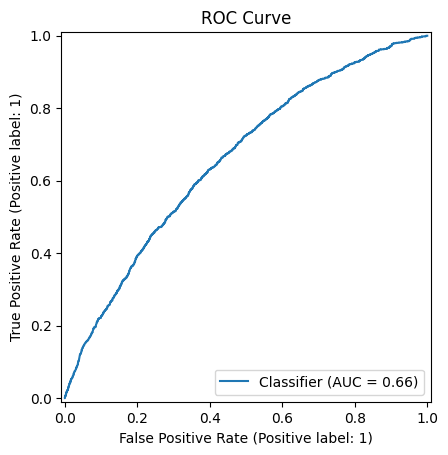

In [78]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve")
plt.show()

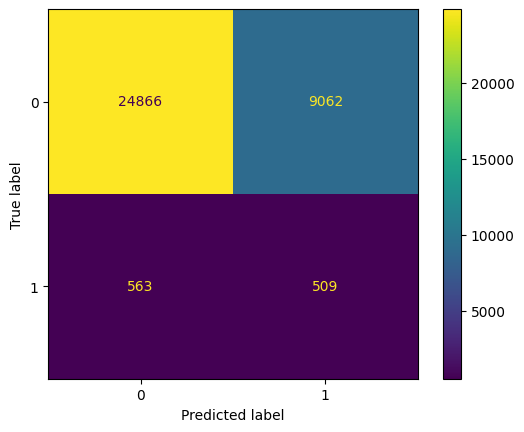

In [79]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test);

In [83]:
acc_train = model.score(X_train_smote, y_train_smote)
acc_test = model.score(X_test, y_test)

print("Training Accuracy:", round(acc_train, 4))
print("Validation Accuracy:", round(acc_test, 4))

Training Accuracy: 0.7612
Validation Accuracy: 0.725


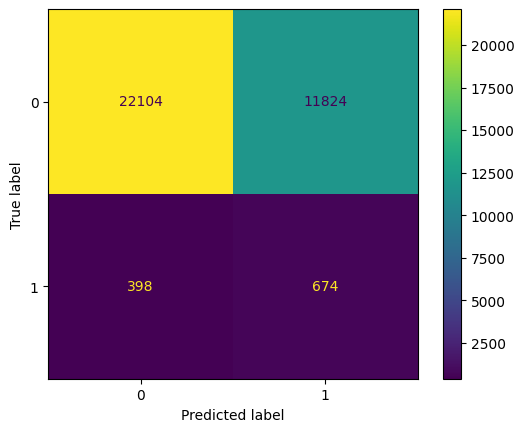

In [67]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test);

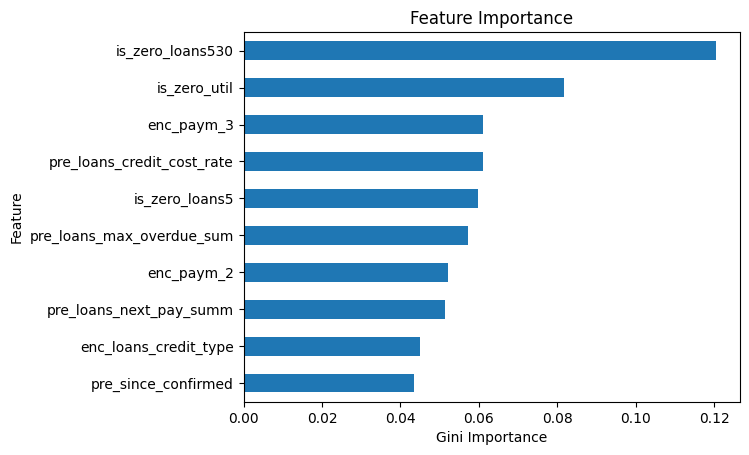

In [85]:
features = X_train_smote.columns

# Extract importances from model
importances = model.best_estimator_.named_steps["gradientboostingclassifier"].feature_importances_

# Create a series with feature names and importances
feat_imp = pd.Series(importances, index=features).sort_values()

# Plot 10 most important features
feat_imp.tail(10).plot(kind="barh")
plt.xlabel("Gini Importance")
plt.ylabel("Feature")
plt.title("Feature Importance");

In [71]:
df_train.corr()['flag'].sort_values(ascending=False)

flag                       1.000000
enc_paym_1                 0.058240
enc_paym_2                 0.057118
enc_paym_3                 0.054696
enc_paym_4                 0.051555
                             ...   
is_zero_loans530          -0.040554
is_zero_loans90           -0.042736
is_zero_loans3060         -0.044835
is_zero_loans6090         -0.046163
pre_loans_total_overdue         NaN
Name: flag, Length: 61, dtype: float64

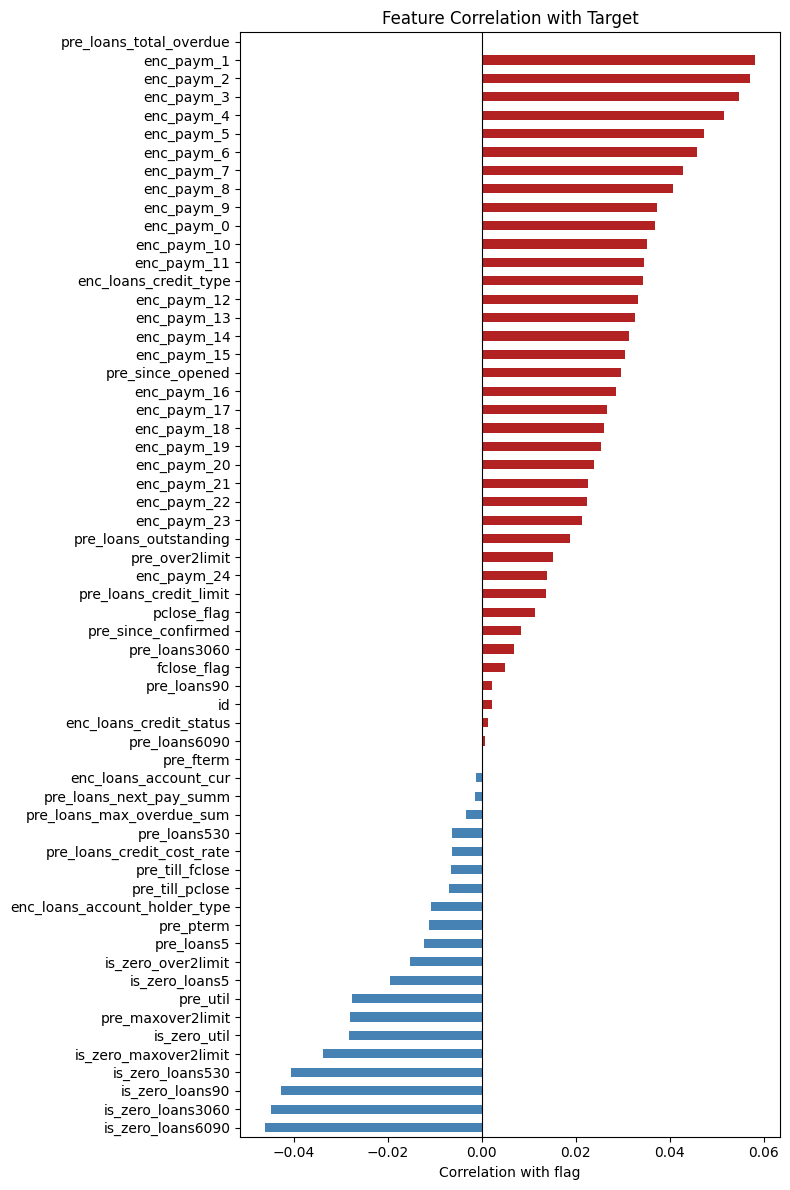

In [86]:
import matplotlib.pyplot as plt

corr_with_target = df_train.corr(numeric_only=True)['flag'].drop('flag').sort_values()

plt.figure(figsize=(8, 12))
corr_with_target.plot(kind='barh', color=(corr_with_target > 0).map({True: 'firebrick', False: 'steelblue'}))
plt.xlabel('Correlation with flag')
plt.title('Feature Correlation with Target')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [111]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

clf = make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=42))

params = {
    "gradientboostingclassifier__n_estimators": [100, 200],
    "gradientboostingclassifier__max_depth": [2, 3, 4],
    "gradientboostingclassifier__learning_rate": [0.01, 0.05]
}

model2 = RandomizedSearchCV(
    clf,
    param_distributions=params,
    n_iter=10,          # how many random combos to try (out of 12 possible here)
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

In [ ]:
model2.fit(X_train_smote, y_train_smote)

In [103]:
import lightgbm as lgb

clf = lgb.LGBMClassifier(random_state=42)

params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "num_leaves": [15, 31, 63],
    "subsample": [0.7, 0.8, 1.0],
}

model2 = RandomizedSearchCV(
    clf, param_distributions=params, n_iter=30, cv=3,
    scoring="roc_auc", n_jobs=-1, random_state=42, verbose=1
)

OSError: dlopen(/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/lightgbm/lib/lib_lightgbm.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib
  Referenced from: /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/lightgbm/lib/lib_lightgbm.dylib
  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/local/lib/libomp/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/local/lib/libomp/libomp.dylib' (no such file), '/usr/lib/libomp.dylib' (no such file)

In [113]:
/bin/bash -c "$(curl -fsSL https://raw.githubusercontent.com/Homebrew/install/HEAD/install.sh)"

NameError: name 'bash' is not defined

In [116]:
import optuna
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 2, 4),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'random_state': 42
    }
    
    clf = GradientBoostingClassifier(**params)
    clf.fit(X_train_smote, y_train_smote)
    
    proba = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, proba)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=5)

print("Best params:", study.best_params)
print("Best ROC-AUC:", study.best_value)

[I 2026-07-03 18:47:15,979] A new study created in memory with name: no-name-c2f2fccd-0c9e-4f3b-b71b-c5a750e40e00
[I 2026-07-03 18:48:16,037] Trial 0 finished with value: 0.655058632723555 and parameters: {'n_estimators': 266, 'max_depth': 2, 'learning_rate': 0.039714764592291216}. Best is trial 0 with value: 0.655058632723555.
[I 2026-07-03 18:48:40,787] Trial 1 finished with value: 0.641471351646331 and parameters: {'n_estimators': 110, 'max_depth': 2, 'learning_rate': 0.01446427101751561}. Best is trial 0 with value: 0.655058632723555.
[I 2026-07-03 18:49:50,537] Trial 2 finished with value: 0.654143627132259 and parameters: {'n_estimators': 212, 'max_depth': 3, 'learning_rate': 0.011788077019574995}. Best is trial 0 with value: 0.655058632723555.
[I 2026-07-03 18:50:50,752] Trial 3 finished with value: 0.658588743238535 and parameters: {'n_estimators': 180, 'max_depth': 3, 'learning_rate': 0.01913597299183199}. Best is trial 3 with value: 0.658588743238535.
[I 2026-07-03 18:52:04,3

Best params: {'n_estimators': 180, 'max_depth': 3, 'learning_rate': 0.01913597299183199}
Best ROC-AUC: 0.658588743238535


In [132]:
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV

clf = CatBoostClassifier(random_state=42, verbose=0)

params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1]
}

model4 = RandomizedSearchCV(clf, param_distributions=params, cv=3, scoring="roc_auc", n_jobs=-1, verbose=1)

In [133]:
model4.fit(X_train_smote, y_train_smote)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","CatBoostClass...42, verbose=0)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.05, ...], 'max_depth': [4, 6, ...], 'n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` de

In [144]:
from sklearn.metrics import classification_report, roc_auc_score

print("=== Train ===")
print(classification_report(y_train_smote, model4.predict(X_train_smote)))
y_proba_train = model4.predict_proba(X_train_smote)[:, 1]
print("ROC-AUC (train):", roc_auc_score(y_train_smote, y_proba_train))

print("\n=== Test ===")
print(classification_report(y_test, model4.predict(X_test)))
y_proba_test = model4.predict_proba(X_test)[:, 1]
print("ROC-AUC (test):", roc_auc_score(y_test, y_proba_test))

=== Train ===
              precision    recall  f1-score   support

           0       0.87      0.91      0.89    135646
           1       0.90      0.87      0.89    135646

    accuracy                           0.89    271292
   macro avg       0.89      0.89      0.89    271292
weighted avg       0.89      0.89      0.89    271292

ROC-AUC (train): 0.9567441539383662

=== Test ===
              precision    recall  f1-score   support

           0       0.97      0.91      0.94     33928
           1       0.07      0.23      0.11      1072

    accuracy                           0.89     35000
   macro avg       0.52      0.57      0.52     35000
weighted avg       0.95      0.89      0.91     35000

ROC-AUC (test): 0.6444999061885222


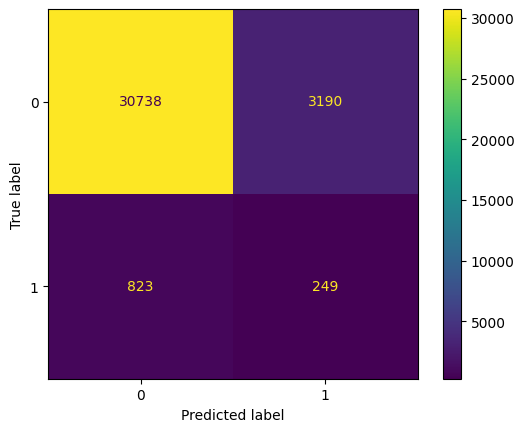

In [135]:
ConfusionMatrixDisplay.from_estimator(model4, X_test, y_test);

In [ ]:

from sklearn.ensemble import RandomForestClassifier

clf = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))

params = {
    "randomforestclassifier__n_estimators": range(100, 201, 50),
    "randomforestclassifier__max_depth": range(2,4)
}

model5 = GridSearchCV(clf, param_grid=params, cv=5, scoring="roc_auc", n_jobs=-1, verbose=1)

In [149]:
model5.fit(X_train_smote, y_train_smote)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'randomforestclassifier__max_depth': [6, 10, ...], 'randomforestclassifier__n_estimators': range(100, 201, 50)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candi

In [150]:
from sklearn.metrics import classification_report, roc_auc_score

print("=== Train ===")
print(classification_report(y_train_smote, model5.predict(X_train_smote)))
y_proba_train = model5.predict_proba(X_train_smote)[:, 1]
print("ROC-AUC (train):", roc_auc_score(y_train_smote, y_proba_train))

print("\n=== Test ===")
print(classification_report(y_test, model5.predict(X_test)))
y_proba_test = model5.predict_proba(X_test)[:, 1]
print("ROC-AUC (test):", roc_auc_score(y_test, y_proba_test))

=== Train ===
              precision    recall  f1-score   support

           0       0.90      0.85      0.87    135646
           1       0.86      0.90      0.88    135646

    accuracy                           0.88    271292
   macro avg       0.88      0.88      0.88    271292
weighted avg       0.88      0.88      0.88    271292

ROC-AUC (train): 0.9537882318796042

=== Test ===
              precision    recall  f1-score   support

           0       0.97      0.85      0.91     33928
           1       0.06      0.31      0.10      1072

    accuracy                           0.83     35000
   macro avg       0.52      0.58      0.50     35000
weighted avg       0.95      0.83      0.88     35000

ROC-AUC (test): 0.6485665457712029


In [154]:

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (140000, 59)
y_train shape: (140000,)
X_test shape: (35000, 59)
y_test shape: (35000,)


In [155]:
features = [
    'enc_paym_1', 'enc_paym_2', 'enc_paym_3', 'is_zero_loans6090',
    'enc_paym_4', 'is_zero_loans3060', 'enc_paym_5', 'is_zero_loans90',
    'enc_paym_6', 'is_zero_loans530', 'enc_paym_7', 'is_zero_maxover2limit',
    'enc_paym_8', 'is_zero_util', 'pre_maxover2limit'
]

X_train = df_train[features]
y_train = df_train['flag']

In [156]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote shape:", X_train_smote.shape)
X_train_smote.head()

X_train_smote shape: (339148, 15)


,enc_paym_1,enc_paym_2,enc_paym_3,is_zero_loans6090,enc_paym_4,is_zero_loans3060,enc_paym_5,is_zero_loans90,enc_paym_6,is_zero_loans530,enc_paym_7,is_zero_maxover2limit,enc_paym_8,is_zero_util,pre_maxover2limit
0,0,1,0,1,0,1,1,1,0,0,0,0,1,1,3
1,0,0,0,1,0,1,0,1,0,1,0,1,0,0,17
2,3,3,3,1,3,1,3,1,3,1,3,1,3,0,17
3,0,0,0,1,0,1,3,1,3,1,3,1,3,0,17
4,0,0,0,1,0,1,0,1,0,1,0,1,0,0,17


In [157]:


X_test = df_test[features]
# y_test — only if df_test has labels; if not, skip evaluation on test

clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train, y_train)

# Evaluate on train (or a held-out val/test set with known labels)
y_proba_train = clf.predict_proba(X_train)[:, 1]
print(classification_report(y_train, clf.predict(X_train)))
print("ROC-AUC (train):", roc_auc_score(y_train, y_proba_train))

              precision    recall  f1-score   support

           0       0.98      0.61      0.75    169574
           1       0.05      0.66      0.10      5426

    accuracy                           0.61    175000
   macro avg       0.52      0.64      0.43    175000
weighted avg       0.95      0.61      0.73    175000

ROC-AUC (train): 0.6903689699977174


In [1]:
import xgboost as xgb
print(xgb.__version__)

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/usr/lib/libomp.dylib' (no such file)"]


In [16]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

clf = xgb.XGBClassifier(random_state=42, eval_metric='logloss')

params = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05]
}

model = RandomizedSearchCV(clf, param_distributions=params, cv=3, scoring="roc_auc", n_jobs=-1, verbose=1)
model.fit(X_train_smote, y_train_smote)

print("Best params:", model.best_params_)
print("Best CV ROC-AUC:", model.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best params: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05}
Best CV ROC-AUC: 0.9211957235871547


In [18]:
from sklearn.metrics import classification_report, roc_auc_score

print("=== Train ===")
print(classification_report(y_train_smote, model.predict(X_train_smote)))
y_proba_train = model.predict_proba(X_train_smote)[:, 1]
print("ROC-AUC (train):", roc_auc_score(y_train_smote, y_proba_train))

print("\n=== Test ===")
print(classification_report(y_test, model.predict(X_test)))
y_proba_test = model.predict_proba(X_test)[:, 1]
print("ROC-AUC (test):", roc_auc_score(y_test, y_proba_test))

=== Train ===
              precision    recall  f1-score   support

           0       0.85      0.82      0.83    135646
           1       0.83      0.85      0.84    135646

    accuracy                           0.84    271292
   macro avg       0.84      0.84      0.84    271292
weighted avg       0.84      0.84      0.84    271292

ROC-AUC (train): 0.9216239448081434

=== Test ===
              precision    recall  f1-score   support

           0       0.98      0.83      0.90     33928
           1       0.06      0.36      0.11      1072

    accuracy                           0.81     35000
   macro avg       0.52      0.59      0.50     35000
weighted avg       0.95      0.81      0.87     35000

ROC-AUC (test): 0.6560423197543876


In [19]:
import optuna
import xgboost as xgb
from sklearn.metrics import roc_auc_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'random_state': 42,
        'eval_metric': 'logloss'
    }
    
    clf = xgb.XGBClassifier(**params)
    clf.fit(X_train, y_train)
    
    proba = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, proba)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best params:", study.best_params)
print("Best ROC-AUC:", study.best_value)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-07-04 01:02:53,375] A new study created in memory with name: no-name-66b2dd38-8a23-45e4-8d9f-99bbf28367b0
[I 2026-07-04 01:02:54,089] Trial 0 finished with value: 0.7036909895010329 and parameters: {'n_estimators': 106, 'max_depth': 6, 'learning_rate': 0.024093260749492484, 'subsample': 0.86779347688708, 'colsample_bytree': 0.8919370761238251}. Best is trial 0 with value: 0.7036909895010329.
[I 2026-07-04 01:02:54,913] Trial 1 finished with value: 0.7068342101535474 and parameters: {'n_estimators': 220, 'max_depth': 3, 'learning_rate': 0.07034907330846393, 'subsample': 0.9828859527339662, 'colsample_bytree': 0.7928497595453818}. Best is trial 1 with value: 0.7068342101535474.
[I 2026-07-04 01:02:56

Best params: {'n_estimators': 144, 'max_depth': 4, 'learning_rate': 0.09009804231289781, 'subsample': 0.8284337733213566, 'colsample_bytree': 0.744622198240817}
Best ROC-AUC: 0.7103251683987514


In [20]:
best_clf = xgb.XGBClassifier(**study.best_params, random_state=42, eval_metric='logloss')
best_clf.fit(X_train, y_train)

from sklearn.metrics import classification_report, roc_auc_score

print("=== Train ===")
print(classification_report(y_train, best_clf.predict(X_train)))
print("ROC-AUC (train):", roc_auc_score(y_train, best_clf.predict_proba(X_train)[:, 1]))

print("\n=== Test ===")
print(classification_report(y_test, best_clf.predict(X_test)))
print("ROC-AUC (test):", roc_auc_score(y_test, best_clf.predict_proba(X_test)[:, 1]))

=== Train ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98    135646
           1       1.00      0.00      0.00      4354

    accuracy                           0.97    140000
   macro avg       0.98      0.50      0.49    140000
weighted avg       0.97      0.97      0.95    140000

ROC-AUC (train): 0.7536064592283499

=== Test ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     33928
           1       0.00      0.00      0.00      1072

    accuracy                           0.97     35000
   macro avg       0.48      0.50      0.49     35000
weighted avg       0.94      0.97      0.95     35000

ROC-AUC (test): 0.7103251683987514


In [21]:
import optuna
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'random_state': 42
    }
    
    clf = lgb.LGBMClassifier(**params, verbose=-1)
    clf.fit(X_train, y_train)
    
    proba = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, proba)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best params:", study.best_params)
print("Best ROC-AUC:", study.best_value)

[I 2026-07-04 01:04:52,836] A new study created in memory with name: no-name-bb18289b-59c1-4d95-adbd-096c8ead7943
[I 2026-07-04 01:04:53,691] Trial 0 finished with value: 0.7003218184601632 and parameters: {'n_estimators': 180, 'max_depth': 4, 'learning_rate': 0.019534535605462155, 'subsample': 0.7938583825884045, 'colsample_bytree': 0.8373014142706148, 'num_leaves': 43}. Best is trial 0 with value: 0.7003218184601632.
[I 2026-07-04 01:04:54,220] Trial 1 finished with value: 0.6897413162245246 and parameters: {'n_estimators': 113, 'max_depth': 3, 'learning_rate': 0.020734327463363372, 'subsample': 0.7623294491884327, 'colsample_bytree': 0.7820196758306394, 'num_leaves': 25}. Best is trial 0 with value: 0.7003218184601632.
[I 2026-07-04 01:04:55,107] Trial 2 finished with value: 0.7097743009120279 and parameters: {'n_estimators': 168, 'max_depth': 6, 'learning_rate': 0.06453588603008112, 'subsample': 0.7642597710086869, 'colsample_bytree': 0.8870164026434292, 'num_leaves': 19}. Best is 

Best params: {'n_estimators': 198, 'max_depth': 6, 'learning_rate': 0.05424486361893645, 'subsample': 0.8300986113788051, 'colsample_bytree': 0.9682036364389284, 'num_leaves': 15}
Best ROC-AUC: 0.7122760044756763


In [22]:
from sklearn.metrics import classification_report, roc_auc_score

best_clf = lgb.LGBMClassifier(**study.best_params, random_state=42, verbose=-1)
best_clf.fit(X_train, y_train)

print("=== Train ===")
print(classification_report(y_train, best_clf.predict(X_train)))
print("ROC-AUC (train):", roc_auc_score(y_train, best_clf.predict_proba(X_train)[:, 1]))

print("\n=== Test ===")
print(classification_report(y_test, best_clf.predict(X_test)))
print("ROC-AUC (test):", roc_auc_score(y_test, best_clf.predict_proba(X_test)[:, 1]))

=== Train ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98    135646
           1       1.00      0.00      0.00      4354

    accuracy                           0.97    140000
   macro avg       0.98      0.50      0.49    140000
weighted avg       0.97      0.97      0.95    140000

ROC-AUC (train): 0.7583467907165826

=== Test ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     33928
           1       0.00      0.00      0.00      1072

    accuracy                           0.97     35000
   macro avg       0.48      0.50      0.49     35000
weighted avg       0.94      0.97      0.95     35000

ROC-AUC (test): 0.7122760044756763


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

In [23]:

from sklearn.ensemble import RandomForestClassifier


def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 4, 15),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'class_weight': 'balanced',
        'random_state': 42,
        'n_jobs': -1
    }
    
    clf = RandomForestClassifier(**params)
    clf.fit(X_train, y_train)
    
    proba = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, proba)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best params:", study.best_params)
print("Best ROC-AUC:", study.best_value)

[I 2026-07-04 01:12:07,600] A new study created in memory with name: no-name-9b0dd773-58ac-4fa4-85d1-c29c2f8bb475
[I 2026-07-04 01:12:10,018] Trial 0 finished with value: 0.6640447934959721 and parameters: {'n_estimators': 156, 'max_depth': 13, 'min_samples_leaf': 7, 'max_features': 'log2'}. Best is trial 0 with value: 0.6640447934959721.
[I 2026-07-04 01:12:10,910] Trial 1 finished with value: 0.6677042797170127 and parameters: {'n_estimators': 142, 'max_depth': 4, 'min_samples_leaf': 3, 'max_features': 'log2'}. Best is trial 1 with value: 0.6677042797170127.
[I 2026-07-04 01:12:12,953] Trial 2 finished with value: 0.6792199273175504 and parameters: {'n_estimators': 167, 'max_depth': 8, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 2 with value: 0.6792199273175504.
[I 2026-07-04 01:12:16,159] Trial 3 finished with value: 0.6729769686773043 and parameters: {'n_estimators': 237, 'max_depth': 10, 'min_samples_leaf': 7, 'max_features': 'log2'}. Best is trial 2 with value: 

Best params: {'n_estimators': 256, 'max_depth': 14, 'min_samples_leaf': 20, 'max_features': 'log2'}
Best ROC-AUC: 0.6847796183621505


In [24]:
from sklearn.metrics import classification_report, roc_auc_score

best_clf = RandomForestClassifier(**study.best_params, class_weight='balanced', random_state=42, n_jobs=-1)
best_clf.fit(X_train, y_train)

print("=== Train ===")
print(classification_report(y_train, best_clf.predict(X_train)))
print("ROC-AUC (train):", roc_auc_score(y_train, best_clf.predict_proba(X_train)[:, 1]))

print("\n=== Test ===")
print(classification_report(y_test, best_clf.predict(X_test)))
print("ROC-AUC (test):", roc_auc_score(y_test, best_clf.predict_proba(X_test)[:, 1]))

=== Train ===
              precision    recall  f1-score   support

           0       0.99      0.75      0.85    135646
           1       0.08      0.70      0.15      4354

    accuracy                           0.75    140000
   macro avg       0.53      0.72      0.50    140000
weighted avg       0.96      0.75      0.83    140000

ROC-AUC (train): 0.8033690911909233

=== Test ===
              precision    recall  f1-score   support

           0       0.98      0.75      0.85     33928
           1       0.06      0.51      0.11      1072

    accuracy                           0.74     35000
   macro avg       0.52      0.63      0.48     35000
weighted avg       0.95      0.74      0.83     35000

ROC-AUC (test): 0.6847796183621505
